# Surtido por tienda con estimación de demanda y sustitución

## Recreación del artículo de Fisher y Vaidyanathan (2014)

Este notebook recrea el procedimiento del artículo *A Demand Estimation Procedure for Retail Assortment Optimization with Results from Implementations* de Marshall Fisher y Ramnath Vaidyanathan, publicado en Management Science en 2014 (DOI 10.1287/mnsc.2014.1904).

El artículo responde una pregunta muy parecida a la de nuestro trabajo de grado. Una cadena tiene un espacio limitado en el estante para una categoría y debe decidir qué productos pone en cada tienda. Para decidir bien necesita saber cuánto se vendería cada producto en cada tienda, incluso los productos que hoy no tiene, y qué pasa cuando un cliente no encuentra su producto favorito y se lleva otro parecido.

Seguimos el caso de los ponqués de una cadena de tiendas de conveniencia, que es el ejemplo con más detalle en el artículo. Como los datos originales no son públicos, primero simulamos datos con la misma estructura que describe el artículo y después aplicamos el procedimiento completo. Al final aplicamos el mismo código a datos públicos reales de yogur, que es una categoría láctea cercana a la de nuestro proyecto.

El notebook avanza en el mismo orden del artículo. Primero preparamos el entorno y explicamos el modelo. Luego simulamos los datos y los exploramos. Después estimamos los precios de los productos que la cadena no vende, estimamos la demanda de cada tienda por máxima verosimilitud y validamos esas estimaciones. Con la demanda estimada elegimos los surtidos, agrupamos las tiendas que deben llevar el mismo surtido y medimos cuánto vale adaptar el surtido a cada tienda. Cerramos con el pronóstico de un producto nuevo, la comparación con los resultados del artículo y la aplicación a datos públicos.

## 1. Preparación del entorno

Cargamos las librerías, fijamos una semilla para que los resultados sean siempre los mismos y creamos las carpetas del proyecto (data, results y figures).

La primera parte de la celda evita que el Mac entre en reposo mientras el notebook corre, porque la estimación tienda por tienda puede tardar varios minutos. Para eso usamos caffeinate, una herramienta que ya viene en macOS. La atamos al proceso del notebook, así que se apaga sola cuando se cierra el notebook. En Windows o Linux esa parte simplemente no hace nada.

In [1]:
# Librerías del sistema
import os
import platform
import subprocess
import sys
import time
import urllib.request
from pathlib import Path

# Evitar que el Mac entre en reposo mientras el notebook esté abierto
if platform.system() == "Darwin":
    # caffeinate mantiene despiertos pantalla, disco y sistema hasta que termine el proceso de este notebook
    subprocess.Popen(["caffeinate", "-dims", "-w", str(os.getpid())])

# Librerías de análisis
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy.optimize import minimize
from scipy import special
from sklearn.linear_model import LinearRegression
from sklearn.metrics import adjusted_rand_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

# Semilla fija para que la simulación y la estimación den siempre lo mismo
SEMILLA = 2005
rng = np.random.default_rng(SEMILLA)  # Generador de números aleatorios

# Carpeta base del proyecto (sube un nivel si el notebook está dentro de la carpeta notebooks)
BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
# Rutas de datos, resultados y figuras
RUTA = {nombre: BASE / nombre for nombre in ("data", "results", "figures")}
# Crear las carpetas si no existen
for carpeta in RUTA.values():
    carpeta.mkdir(exist_ok=True)  # Crear la carpeta

# Estilo sobrio para los gráficos
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold"})
# Colores fijos por serie
COLOR = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"]
# Mostrar las tablas con tres decimales
pd.set_option("display.float_format", "{:.3f}".format)

## 2. El modelo del artículo

**Productos como combinación de atributos.** En los ponqués hay dos atributos. El primero es el sabor, con 23 niveles. El segundo combina marca y tamaño, con 4 niveles (marca 1 o marca 2, en tamaño individual o familiar). Eso da 23 por 4, es decir 92 productos posibles.

**Demanda de cada producto.** En cada tienda $s$ el artículo supone que la fracción de clientes que prefiere el producto $i$ es el producto de las fracciones de sus atributos.

$$f^s_i = f^s_{\text{sabor}(i)} \times f^s_{\text{marca y tamaño}(i)}$$

Por ejemplo, si en una tienda el 10% de los clientes prefiere chocolate y el 61% prefiere la marca 1 individual, el 6,1% prefiere el ponqué de chocolate de marca 1 individual.

**Sustitución.** Si el producto favorito $i$ no está en el surtido $S$, el cliente compra su mejor sustituto $j(i,S)$ con probabilidad $\pi_{ij}$, o se va sin comprar. En los ponqués el artículo asume que nadie cambia de sabor ni de tamaño. Solo se cambia de marca dentro del mismo sabor y tamaño. Así, la probabilidad de que un cliente compre el producto $j$ es

$$F_j(S) = f_j + \sum_{i \notin S,\ j(i,S)=j} f_i \, \pi_{ij}$$

que son sus clientes propios más los que llegan porque su favorito no estaba.

**Estimación.** Con las ventas $x_j$ de los productos que la tienda tiene, se buscan las fracciones $f$ y las probabilidades $\pi$ que hacen más probable lo que se observó. Eso es la máxima verosimilitud.

$$\text{LLH}(f,\pi) = \sum_{j \in S} x_j \log \frac{F_j(S)}{F(S)}$$

Aquí $F(S)$ es la suma de todos los $F_j(S)$. Con eso también se estima la demanda total de la categoría en la tienda, $D = \text{ventas totales} / F(S)$, y la demanda de cada producto, $D_i = f_i \, D$, incluso de los que la tienda no tiene.

**Optimización.** El ingreso de la tienda con el surtido $S$ suma lo que compran los clientes que encuentran su favorito y lo que compran los que sustituyen.

$$R_s(S) = \sum_{i \in S} p_i D^s_i + \sum_{i \notin S} D^s_i \, \pi_{i,j(i,S)} \, p_{j(i,S)}$$

El problema es elegir como máximo $K$ productos por surtido y como máximo $L$ surtidos distintos en la cadena para que la suma de $R_s$ sea la mayor posible. Las tiendas que terminan con el mismo surtido forman un grupo, y así salen los clusters de tiendas.

La siguiente celda define estas piezas como funciones. Las escribimos una sola vez y las usamos tanto con los datos simulados como con los datos públicos.

In [2]:
def normalizar(v):
    """Divide cada fila por su suma para que quede como proporciones."""
    return v / v.sum(axis=-1, keepdims=True)


def estructura(a1, a2, pares, prioridad=None):
    """Arma la estructura del modelo: atributos de cada producto y sus posibles sustitutos.

    pares es un diccionario {(nivel de origen, nivel de destino): número de parámetro} del atributo 2.
    La sustitución solo ocurre entre productos con el mismo nivel del atributo 1.
    prioridad sirve para desempatar cuando dos sustitutos tienen la misma probabilidad."""
    a1, a2 = np.asarray(a1), np.asarray(a2)  # Pasar los atributos a arreglos de numpy
    # Lista de sustitutos posibles de cada producto con el número de su parámetro
    lista = [[(j, pares[(a2[i], a2[j])]) for j in range(len(a1)) if a1[i] == a1[j] and (a2[i], a2[j]) in pares]
             for i in range(len(a1))]
    # Máximo número de sustitutos que tiene un producto
    m = max(1, max(map(len, lista)))
    # Matriz de sustitutos, rellenando los huecos con el mismo producto
    cand = np.array([[j for j, _ in l] + [i] * (m - len(l)) for i, l in enumerate(lista)])
    # Matriz con el parámetro de cada sustituto, los huecos llevan el parámetro vacío (probabilidad cero)
    cpar = np.array([[k for _, k in l] + [-1] * (m - len(l)) for l in lista])
    # Guardar todo en un diccionario
    return {"a1": a1, "a2": a2, "n1": a1.max() + 1, "n2": a2.max() + 1, "cand": cand, "cpar": cpar,
            "n_pi": max(pares.values()) + 1,
            "prio": np.zeros(len(a1)) if prioridad is None else np.asarray(prioridad, float)}


def prob_compra(f, Pc, S, est):
    """Calcula F_j(S): probabilidad de que un cliente compre cada producto j con el surtido S.

    Funciona para una tienda o para muchas a la vez (la primera dimensión son las tiendas)."""
    # Usar el mismo surtido para todas las tiendas si viene uno solo
    S = np.broadcast_to(S, f.shape)
    # Puntaje de cada sustituto, solo vale si está en el surtido y tiene probabilidad positiva
    puntaje = np.where(S[..., est["cand"]] & (Pc > 0), Pc + 1e-9 * est["prio"][est["cand"]], -1.0)
    # Posición del mejor sustituto disponible
    k = puntaje.argmax(axis=-1)[..., None]
    # Producto que corresponde a ese mejor sustituto
    j = np.take_along_axis(np.broadcast_to(est["cand"], puntaje.shape), k, axis=-1)[..., 0]
    # Probabilidad de sustituir, cero si no hay ningún sustituto disponible
    prob = np.take_along_axis(Pc, k, axis=-1)[..., 0] * (puntaje.max(axis=-1) > 0)
    # Desplazamiento por tienda para sumar todo en un solo vector
    n = f.shape[-1]
    filas = np.arange(f.size // n).reshape(f.shape[:-1] + (1,)) * n  # Desplazamiento de cada tienda
    # Clientes propios más los clientes que llegan desde productos ausentes
    return f * S + np.bincount((j + filas).ravel(), (f * prob * ~S).ravel(), minlength=f.size).reshape(f.shape)


def desempacar(theta, est):
    """Convierte el vector de parámetros libres en cuotas de demanda f y probabilidades de sustitución."""
    n1, n2 = est["n1"], est["n2"]
    # Cuotas de cada nivel del atributo 1 (softmax garantiza que sumen 1)
    f1 = special.softmax(np.append(theta[: n1 - 1], 0.0))
    # Cuotas de cada nivel del atributo 2
    f2 = special.softmax(np.append(theta[n1 - 1 : n1 + n2 - 2], 0.0))
    # Probabilidades de sustitución entre 0 y 1, más un cero para los huecos
    pi = np.append(special.expit(theta[n1 + n2 - 2 :]), 0.0)
    # Cuota de cada producto y probabilidad hacia cada sustituto
    return f1[est["a1"]] * f2[est["a2"]], pi[est["cpar"]]


def neg_logver(theta, x, S, est, centro=0.0, lam=0.0):
    """Menos la log verosimilitud de las ventas x de una tienda con surtido S.

    Si lam es mayor que cero se suma una penalización pequeña por alejarse del centro de la cadena."""
    # Probabilidad de compra de los productos del surtido
    F = prob_compra(*desempacar(theta, est), S, est)[S]
    # Ventas por logaritmo de la cuota esperada (negativo porque minimize busca mínimos) más la penalización
    return -np.sum(x[S] * np.log(F / F.sum() + 1e-12)) + lam * np.sum((theta - centro) ** 2)


def estimar_tienda(x, S, est, inicios, centro=0.0, lam=0.0, pi_fijo=None):
    """Estima por máxima verosimilitud los parámetros de una tienda desde varios puntos de partida.

    Si pi_fijo viene, solo se estiman las cuotas y las probabilidades de sustitución quedan fijas."""
    # Función a minimizar con todos los parámetros o solo con las cuotas
    if pi_fijo is None:
        objetivo = lambda th: neg_logver(th, x, S, est, centro, lam)  # Se estiman cuotas y sustituciones
    else:
        objetivo = lambda th: neg_logver(np.append(th, pi_fijo), x, S, est)  # Se estiman solo las cuotas
    # Optimizar desde cada punto de partida y quedarse con el mejor, porque puede haber varios máximos (sección 4.1)
    return min((minimize(objetivo, t0, method="L-BFGS-B", bounds=[(-10, 10)] * len(t0)) for t0 in inicios),
               key=lambda r: r.fun).x


def neg_logver_cadena(pi_logit, theta_f, X, S, est):
    """Menos la log verosimilitud de toda la cadena con sustituciones comunes y cuotas de cada tienda fijas."""
    # Cuotas de cada tienda (no dependen de la sustitución)
    f = np.array([desempacar(np.append(th, pi_logit), est)[0] for th in theta_f])
    # Probabilidad hacia cada sustituto, igual para todas las tiendas
    Pc = np.broadcast_to(np.append(special.expit(pi_logit), 0.0)[est["cpar"]], (len(X),) + est["cpar"].shape)
    # Probabilidad de compra de cada producto del surtido en cada tienda
    F = prob_compra(f, Pc, S, est) * S
    # Suma de la log verosimilitud de todas las tiendas
    return -np.sum(X * np.log(F / F.sum(1, keepdims=True) + 1e-12))


def estimar_cadena(X, S, est, precios, lam=1.0, rondas=3):
    """Estima el modelo de todas las tiendas y devuelve el modelo completo de la cadena.

    Primero alterna entre cuotas por tienda y sustituciones comunes para encontrar el centro de la cadena.
    Después estima cada tienda con todos sus parámetros, con una penalización pequeña por alejarse de ese centro."""
    # Parámetros de cuotas por tienda y sustituciones en escala logit (cero equivale a probabilidad 0,5)
    theta_f = np.zeros((len(X), est["n1"] + est["n2"] - 2))
    pi_logit = np.zeros(est["n_pi"])  # Sustituciones iniciales de 0,5
    for _ in range(rondas):  # Alternar varias rondas
        # Cuotas de cada tienda con las sustituciones fijas, usando todos los núcleos del computador
        theta_f = np.array(Parallel(n_jobs=-1)(delayed(estimar_tienda)(x, s, est, [th], pi_fijo=pi_logit)
                                               for x, s, th in zip(X, S, theta_f)))
        # Sustituciones comunes de la cadena con las cuotas fijas
        pi_logit = minimize(neg_logver_cadena, pi_logit, args=(theta_f, X, S, est), method="L-BFGS-B",
                            bounds=[(-10, 10)] * est["n_pi"]).x
    # Centro de la cadena: mediana de las cuotas y sustituciones comunes
    centro = np.append(np.median(theta_f, axis=0), pi_logit)
    # Vuelta final por tienda desde tres puntos: lo encontrado, el centro y uno al azar
    rng_e = np.random.default_rng(SEMILLA)
    theta = np.array(Parallel(n_jobs=-1)(delayed(estimar_tienda)(x, s, est, [np.append(th, pi_logit), centro, rng_e.normal(0, 1, len(centro))], centro, lam)
                                         for x, s, th in zip(X, S, theta_f)))
    # Pasar a cuotas de demanda y probabilidades de sustitución
    f, Pc = map(np.array, zip(*(desempacar(th, est) for th in theta)))
    # Demanda total de la categoría: ventas dividido probabilidad de comprar algo del surtido
    D = X.sum(1) / (prob_compra(f, Pc, S, est) * S).sum(1)
    return {"f": f, "Pc": Pc, "D": D, "pi": special.expit(theta[:, len(theta_f[0]):]),
            "p": np.asarray(precios, float), "est": est}


def ingreso(modelo, S):
    """Ingreso esperado de cada tienda con el surtido S (clientes propios más los que sustituyen)."""
    return modelo["D"] * (prob_compra(modelo["f"], modelo["Pc"], S, modelo["est"]) @ modelo["p"])


def mad(X, S, modelo):
    """Error MAD ponderado por ventas entre cuotas observadas y estimadas, en tienda y en cadena (sección 5.3)."""
    # Cuotas estimadas de cada producto del surtido
    estimada = normalizar(prob_compra(modelo["f"], modelo["Pc"], S, modelo["est"]) * S)
    # Cuotas observadas
    observada = normalizar(X)
    # Nivel tienda: diferencia absoluta de cuotas, ponderada por las ventas de cada tienda
    tienda = np.sum(X.sum(1) * np.abs(observada - estimada).sum(1)) / X.sum()
    # Nivel cadena: se suman las ventas de todas las tiendas antes de comparar
    cadena = np.abs(normalizar(X.sum(0)) - normalizar((estimada * X.sum(1, keepdims=True)).sum(0))).sum()
    return tienda, cadena


def greedy(modelo, K, por_tienda=True):
    """Heurística greedy (sección 4.3): agrega uno a uno el producto que más sube el ingreso.

    Devuelve el orden en que entran los productos. El surtido de tamaño k son los primeros k."""
    n_t, n = modelo["f"].shape  # Número de tiendas y de productos
    # Un surtido por tienda o uno solo para toda la cadena
    S = np.zeros((n_t if por_tienda else 1, n), bool)
    orden = np.zeros((len(S), K), int)  # Aquí se guarda el orden en que entran los productos
    for paso in range(K):  # Llenar los K espacios uno por uno
        # Ingreso de cada tienda al agregar cada producto candidato
        ganancia = np.stack([ingreso(modelo, S | (np.arange(n) == c)) for c in range(n)], axis=-1)
        # Para la cadena se suma el ingreso de todas las tiendas
        ganancia = ganancia if por_tienda else ganancia.sum(0, keepdims=True)
        # Los productos que ya están no se pueden volver a elegir
        ganancia[S] = -np.inf
        # Agregar el mejor candidato
        orden[:, paso] = ganancia.argmax(1)
        S[np.arange(len(S)), orden[:, paso]] = True  # Marcarlo como parte del surtido
    return orden


def surtido(orden, k, n):
    """Convierte el orden greedy en una matriz de surtidos con k productos por fila (k puede variar por fila)."""
    S = np.zeros((len(orden), n), bool)
    for fila, (o, kk) in enumerate(zip(orden, np.broadcast_to(k, len(orden)))):  # Recorrer cada fila con su tamaño
        S[fila, o[:kk]] = True  # Tomar los primeros k productos del orden
    return S


def intercambio(modelo, S):
    """Heurística de intercambio (sección 4.3): cambia un producto de adentro por uno de afuera mientras suba el ingreso."""
    S = S.copy()
    while True:  # Repetir hasta que ningún cambio mejore
        # Todos los cambios posibles de un producto de adentro por uno de afuera
        cambios = [(d, a) for d in np.flatnonzero(S[0]) for a in np.flatnonzero(~S[0])]
        # Ingreso total de la cadena con cada cambio
        valor = [ingreso(modelo, np.where(np.isin(np.arange(S.shape[1]), [d, a]), ~S, S)).sum() for d, a in cambios]
        # Parar si ningún cambio mejora el ingreso actual
        if max(valor) <= ingreso(modelo, S).sum() + 1e-6:
            return S
        # Aplicar el mejor cambio
        S[0, list(cambios[int(np.argmax(valor))])] ^= True

## 3. Simulación de los datos

Los datos del artículo son de una cadena real y no están publicados. Por eso los simulamos, usando el mismo modelo del artículo como receta para generar las ventas.

**Lo que tomamos del artículo.** La cadena tiene 140 tiendas, 23 sabores y 4 niveles de marca y tamaño, es decir 92 productos posibles, de los cuales vende 52. Cada tienda tiene entre 24 y 52 productos, con un promedio cercano a 40, y las tiendas pequeñas llevan una parte del surtido de las grandes. Las cuotas de demanda promedio por marca y tamaño son 61%, 27%, 6% y 6% (tabla 3) y las probabilidades de sustitución entre marcas son las de la tabla 4. Hay un periodo de ajuste (julio a diciembre de 2005) y uno de validación (julio a diciembre de 2007) que solo tiene datos de 54 tiendas, y en la validación aparece un producto nuevo de la marca 2 individual.

**Lo que suponemos nosotros y por qué.** El artículo no dice cómo cambian los gustos entre tiendas. Creamos cuatro tipos de tienda ocultos, cada uno con preferencias un poco distintas, y cada tienda varía alrededor de su tipo. Así podemos revisar después si los grupos que salen del método recuperan esos tipos. La popularidad de los sabores baja de forma gradual, porque el artículo dice que 23 de 60 sabores suman el 95% de las ventas. En los precios, el tamaño familiar cuesta cerca de tres veces el individual y cada sabor tiene una pequeña diferencia.

El surtido actual sale de una regla heredada que ordena los productos por su ingreso promedio pero lo conoce con mucho error, porque el artículo encontró que el surtido optimizado vende cerca de 30% más que el actual. Además, agregamos un ruido propio de cada producto en cada tienda, porque en la realidad la demanda no es exactamente el producto de las cuotas de los atributos (el artículo lo discute en la sección 3). Ese ruido hace que el modelo no sea perfecto, igual que con datos reales. Por último, entre 2005 y 2007 los gustos cambian (con un ruido de 35% por producto) y la demanda crece 5%.

In [3]:
# Parámetros que reporta el artículo para los ponqués
N_TIENDAS = 140                                                   # tiendas de la cadena
SABORES = [f"Sabor {k + 1:02d}" for k in range(23)]               # 23 sabores que suman el 95% de las ventas
MARCA_TAM = ["B1 Individual", "B2 Individual", "B1 Familiar", "B2 Familiar"]  # niveles de marca y tamaño
CUOTA_MARCA = np.array([0.61, 0.27, 0.06, 0.06])                  # cuota de demanda por marca y tamaño (tabla 3)
PI_ARTICULO = {(0, 1): 0.18, (1, 0): 0.26, (2, 3): 0.89, (3, 2): 0.22}  # sustitución entre marcas (tabla 4)
N_OFRECIDOS = 52                                                  # productos que la cadena vende en alguna tienda
K_MIN, K_MAX = 24, 52                                             # rango de productos por tienda
N_TIENDAS_VALID = 54                                              # tiendas con datos en la validación

# Supuestos propios porque el artículo no los reporta
N_TIPOS = 4                                    # tipos de tienda ocultos que generan diferencias locales
CONC_TIENDA = 150                              # qué tanto se parece cada tienda a su tipo (más alto, más parecido)
CONC_PI = 40                                   # qué tanto varía la sustitución entre tiendas (más alto, menos)
RUIDO_PRODUCTO = 0.30                          # ruido propio de cada producto en cada tienda
DEMANDA_MEDIA = 30000                          # clientes potenciales de la categoría por tienda en seis meses
PRECIO_BASE = np.array([1.29, 1.19, 3.99, 3.79])  # precio base en dólares por marca y tamaño
CRECIMIENTO = 1.05                             # crecimiento de la demanda entre 2005 y 2007

# Catálogo de los 92 productos posibles (cada sabor con cada marca y tamaño)
productos = pd.MultiIndex.from_product([SABORES, MARCA_TAM], names=["sabor", "marca_tam"]).to_frame(index=False)
# Código numérico del sabor (atributo 1) y de la marca y tamaño (atributo 2)
productos["a1"] = productos.index // len(MARCA_TAM)
productos["a2"] = productos.index % len(MARCA_TAM)  # Código de marca y tamaño
N_PROD = len(productos)  # Número de productos posibles

# Estructura de sustitución de los ponqués: solo entre marcas del mismo sabor y tamaño
EST = estructura(productos["a1"], productos["a2"], {par: k for k, par in enumerate(PI_ARTICULO)})

In [4]:
# Popularidad de los sabores en la cadena, va bajando poco a poco del primero al último
base_sabor = 1 / np.arange(1, len(SABORES) + 1) ** 0.6
# Perfil de sabores de cada tipo de tienda (la base con una inclinación propia)
perfil_sabor = normalizar(base_sabor * rng.lognormal(0, 1.0, (N_TIPOS, len(SABORES))))
# Perfil de marca y tamaño de cada tipo de tienda con una inclinación propia
perfil_marca = CUOTA_MARCA * rng.lognormal(0, 0.7, (N_TIPOS, len(MARCA_TAM)))
# Ajustar los perfiles para que el promedio de los tipos sea la cuota del artículo
perfil_marca = normalizar(perfil_marca * CUOTA_MARCA / perfil_marca.mean(0))

# Tabla de tiendas con su tipo oculto y su tamaño relativo
tiendas = pd.DataFrame({"tienda": np.arange(N_TIENDAS), "tipo": rng.integers(0, N_TIPOS, N_TIENDAS),
                        "tamano": rng.lognormal(0, 0.45, N_TIENDAS)})
# Productos por tienda: las más grandes tienen más espacio (promedio cercano a 40)
tiendas["k_actual"] = np.round(K_MIN + (K_MAX - K_MIN) * tiendas["tamano"].rank(pct=True) ** 0.72).astype(int)

# Cuotas verdaderas de cada tienda por atributo, alrededor del perfil de su tipo
f_sabor = np.array([rng.dirichlet(CONC_TIENDA * perfil_sabor[t]) for t in tiendas["tipo"]])
f_marca = np.array([rng.dirichlet(CONC_TIENDA * perfil_marca[t]) for t in tiendas["tipo"]])  # Cuotas de marca y tamaño
# Demanda verdadera de cada producto: producto de los atributos por un ruido propio de cada tienda
f_real = normalizar(f_sabor[:, productos["a1"]] * f_marca[:, productos["a2"]]
                    * rng.lognormal(0, RUIDO_PRODUCTO, (N_TIENDAS, N_PROD)))

# Probabilidades verdaderas de sustitución de cada tienda alrededor de la tabla 4
media_pi = np.array(list(PI_ARTICULO.values()))
pi_real = rng.beta(CONC_PI * media_pi, CONC_PI * (1 - media_pi), (N_TIENDAS, len(media_pi)))  # Una probabilidad por tienda y par de marcas
# Probabilidad verdadera de cada producto hacia su sustituto (cero en los huecos)
P_real = np.append(pi_real, np.zeros((N_TIENDAS, 1)), axis=1)[:, EST["cpar"]]

# Precio de cada producto: base por marca y tamaño, efecto del sabor y un ruido propio
productos["precio"] = np.round(PRECIO_BASE[productos["a2"]] * rng.lognormal(0, 0.12, len(SABORES))[productos["a1"]]
                               * rng.lognormal(0, 0.15, N_PROD), 2)

In [5]:
# Puntaje heredado de la cadena: ingreso promedio de cada producto, conocido con mucho error
puntaje = f_real.mean(0) * productos["precio"].to_numpy() * rng.lognormal(0, 1.3, N_PROD)
# Mejor producto de cada sabor según ese puntaje (así toda tienda tiene todos los sabores)
mejor_sabor = pd.Series(puntaje).groupby(productos["a1"]).idxmax().to_numpy()
mejor_sabor = mejor_sabor[np.argsort(-puntaje[mejor_sabor])]  # Ordenarlos de mayor a menor puntaje
# Resto de productos ordenados por puntaje
resto = np.argsort(-puntaje)
resto = resto[~np.isin(resto, mejor_sabor)]  # Quitar los que ya están en la lista
# Lista de la cadena: primero un producto por sabor y luego los demás, hasta 52 productos
orden_actual = np.concatenate([mejor_sabor, resto])[:N_OFRECIDOS]

# Surtido actual: cada tienda lleva los primeros k productos de la lista de la cadena
S_real = surtido(np.tile(orden_actual, (N_TIENDAS, 1)), tiendas["k_actual"].to_numpy(), N_PROD)
# Algunas tiendas cambian un producto por otro de la lista (un poco de localización como en el artículo)
for s in np.flatnonzero((rng.random(N_TIENDAS) < 0.7) & (tiendas["k_actual"] < N_OFRECIDOS)):
    k = tiendas.at[s, "k_actual"]  # Productos que tiene la tienda
    # Sacar dos productos que no son el principal de su sabor y meter dos de los que la tienda no tenía
    S_real[s, rng.choice(orden_actual[len(SABORES):k], 2, replace=False)] = False
    S_real[s, rng.choice(orden_actual[k:], min(2, N_OFRECIDOS - k), replace=False)] = True


def simular_ventas(f, Pc, S, D):
    """Simula unidades vendidas: compradores que encuentran algo en el surtido, repartidos entre los productos."""
    # Probabilidad de compra de cada producto del surtido
    F = prob_compra(f, Pc, S, EST) * S
    # Número de compradores de la categoría en cada tienda
    compradores = rng.poisson(D * F.sum(1))
    # Reparto de los compradores entre los productos
    return np.array([rng.multinomial(c, p / p.sum()) for c, p in zip(compradores, F)])


# Demanda potencial de cada tienda en 2005
D_real = DEMANDA_MEDIA * tiendas["tamano"].to_numpy()
# Ventas del periodo de ajuste (julio a diciembre de 2005)
X_ajuste = simular_ventas(f_real, P_real, S_real, D_real)

# Tiendas con datos en 2007 (solo 54, como en el artículo)
valid = np.sort(rng.choice(N_TIENDAS, N_TIENDAS_VALID, replace=False))
# Gustos de 2007: cambian un poco frente a 2005
f_2007 = normalizar(f_real[valid] * rng.lognormal(0, 0.35, (N_TIENDAS_VALID, N_PROD)))
# Producto nuevo: el de marca 2 individual con más demanda que la cadena no vendía (como el de butterscotch)
nuevo = max(set(np.flatnonzero(productos["a2"] == 1)) - set(orden_actual), key=lambda i: f_real[:, i].mean())
# Surtido de 2007: el mismo de 2005 más el producto nuevo
S_2007 = S_real[valid] | (np.arange(N_PROD) == nuevo)
# Ventas del periodo de validación (julio a diciembre de 2007)
X_2007 = simular_ventas(f_2007, P_real[valid], S_2007, D_real[valid] * CRECIMIENTO)

In [6]:
def tabla_larga(X, S, periodo, ids):
    """Pasa una matriz tienda por producto a una tabla con una fila por producto en surtido."""
    t, i = np.nonzero(S)
    return pd.DataFrame({"periodo": periodo, "tienda": ids[t], "producto": i, "unidades": X[t, i]})


# Guardar ventas de los dos periodos en un CSV
ventas = pd.concat([tabla_larga(X_ajuste, S_real, "ajuste", np.arange(N_TIENDAS)),
                    tabla_larga(X_2007, S_2007, "validacion", valid)], ignore_index=True)
ventas.to_csv(RUTA["data"] / "ventas_simuladas.csv", index=False)  # Guardar CSV de ventas
# Guardar el catálogo: la cadena solo conoce el precio de los productos que vende
catalogo = productos[["sabor", "marca_tam", "a1", "a2"]].assign(
    precio=productos["precio"].where(S_real.any(0) | S_2007.any(0)))
catalogo.to_csv(RUTA["data"] / "productos_simulados.csv", index_label="producto")  # Guardar CSV de productos
# Guardar la tabla de tiendas (el tipo oculto solo se usa al final para evaluar los grupos)
tiendas.to_csv(RUTA["data"] / "tiendas_simuladas.csv", index=False)

# Guardar la verdad de la simulación para comparar al final, y borrar lo que ya no se usa
VERDAD = {"f": f_real, "Pc": P_real, "D": D_real, "pi": pi_real, "p": productos["precio"].to_numpy(),
          "est": EST}
del (base_sabor, perfil_sabor, perfil_marca, f_sabor, f_marca, f_real, media_pi, pi_real, P_real, puntaje,
     mejor_sabor, resto, orden_actual, S_real, D_real, X_ajuste, f_2007, S_2007, X_2007, ventas, catalogo, tiendas)
print("Archivos guardados en", RUTA["data"].relative_to(BASE))  # Confirmar dónde quedaron los archivos

Archivos guardados en data


## 4. Exploración de los datos

Desde aquí trabajamos como si los datos fueran reales. Los leemos de los CSV y solo usamos lo que una cadena podría observar, que son las ventas, el surtido de cada tienda y los precios de lo que vende. Revisamos que los datos simulados se parezcan a lo que describe el artículo y buscamos valores atípicos.

In [7]:
# Cargar CSV de ventas, productos y tiendas
ventas = pd.read_csv(RUTA["data"] / "ventas_simuladas.csv")
catalogo = pd.read_csv(RUTA["data"] / "productos_simulados.csv", index_col="producto")  # Catálogo de productos
tiendas = pd.read_csv(RUTA["data"] / "tiendas_simuladas.csv")  # Tabla de tiendas


def matrices(df, ids, n):
    """Convierte la tabla larga en matriz de unidades y matriz de surtido (tienda por producto)."""
    tabla = df.pivot_table(index="tienda", columns="producto", values="unidades", aggfunc="sum").reindex(index=ids, columns=range(n))
    return tabla.fillna(0).to_numpy(), tabla.notna().to_numpy()


# Matrices del periodo de ajuste (todas las tiendas)
X_fit, S_fit = matrices(ventas.query("periodo == 'ajuste'"), tiendas["tienda"], N_PROD)
# Tiendas y matrices del periodo de validación
valid = np.sort(ventas.query("periodo == 'validacion'")["tienda"].unique())
X_val, S_val = matrices(ventas.query("periodo == 'validacion'"), valid, N_PROD)

# Coincidencia de surtidos entre pares de tiendas: productos en común sobre el surtido más pequeño (sección 5.1)
comunes = S_fit.astype(int) @ S_fit.T.astype(int)
coincidencia = comunes / np.minimum.outer(S_fit.sum(1), S_fit.sum(1))  # Dividir por el surtido más pequeño del par
# Resumen frente a lo que reporta el artículo
pd.DataFrame({"artículo": [140, 92, 52, "24 a 52", 40.3, "97,1%"],
              "simulación": [len(tiendas), N_PROD, S_fit.any(0).sum(), f"{S_fit.sum(1).min()} a {S_fit.sum(1).max()}",
                             round(S_fit.sum(1).mean(), 1), f"{coincidencia[np.triu_indices(len(tiendas), 1)].mean():.1%}"]},
             index=["tiendas", "productos posibles", "productos que vende la cadena", "productos por tienda",
                    "promedio de productos por tienda", "coincidencia promedio de surtidos"])

,artículo,simulación
tiendas,140,140
productos posibles,92,92
productos que vende la cadena,52,52
productos por tienda,24 a 52,25 a 52
promedio de productos por tienda,40.300,40.400
coincidencia promedio de surtidos,"97,1%",96.8%


Tiendas con ventas atípicas: 4 de 140


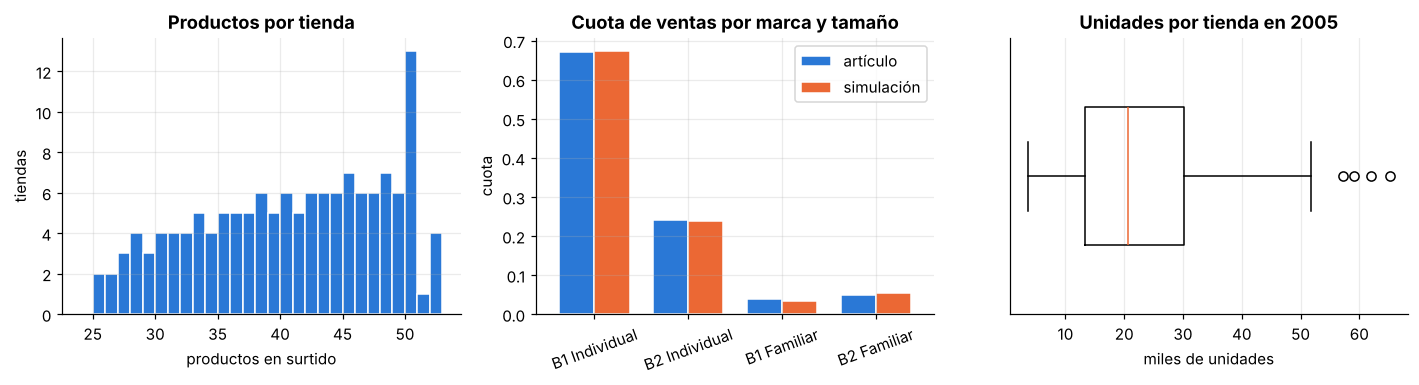

In [8]:
# Cuota de ventas por marca y tamaño frente a la tabla 3 del artículo
cuota_ventas = pd.Series(X_fit.sum(0), index=catalogo["marca_tam"]).groupby(level=0, sort=False).sum()
cuota_ventas = (cuota_ventas / cuota_ventas.sum()).rename("simulación")  # Pasar a proporciones

# Revisar outliers: tiendas con ventas totales fuera de 1,5 rangos intercuartílicos
total_tienda = pd.Series(X_fit.sum(1), name="unidades")
q1, q3 = total_tienda.quantile([0.25, 0.75])  # Primer y tercer cuartil
atipicas = total_tienda[(total_tienda < q1 - 1.5 * (q3 - q1)) | (total_tienda > q3 + 1.5 * (q3 - q1))]  # Tiendas fuera de los límites
print(f"Tiendas con ventas atípicas: {len(atipicas)} de {len(total_tienda)}")  # Mostrar cuántas son

# Gráficos de exploración
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
# Productos por tienda
ax[0].hist(S_fit.sum(1), bins=range(K_MIN, K_MAX + 2), color=COLOR[0], edgecolor="white")
ax[0].set(title="Productos por tienda", xlabel="productos en surtido", ylabel="tiendas")  # Títulos del gráfico
# Cuota de ventas por marca y tamaño frente al artículo
pd.DataFrame({"artículo": [0.67, 0.24, 0.04, 0.05], "simulación": cuota_ventas.values}, index=MARCA_TAM).plot.bar(
    ax=ax[1], color=COLOR[:2], rot=20, width=0.75, edgecolor="white")
ax[1].set(title="Cuota de ventas por marca y tamaño", ylabel="cuota")  # Títulos del gráfico
# Ventas por tienda para ver valores atípicos
ax[2].boxplot(total_tienda / 1000, orientation="horizontal", widths=0.5, medianprops={"color": COLOR[1]})
ax[2].set(title="Unidades por tienda en 2005", xlabel="miles de unidades", yticks=[])  # Títulos del gráfico
fig.tight_layout()  # Ajustar márgenes
fig.savefig(RUTA["figures"] / "01_exploracion.png", bbox_inches="tight")  # Guardar la figura
plt.show()  # Mostrar la figura

La simulación reproduce la estructura del artículo. El rango de productos por tienda, el promedio cercano a 40 y la coincidencia de surtidos se parecen a lo reportado, y esa coincidencia tan alta indica que hoy casi no hay localización. La cuota de ventas por marca y tamaño queda cerca de la tabla 3. Las tiendas con ventas altas que marca la caja son tiendas grandes, no errores, así que no se eliminan. En el artículo la diferencia de tamaño entre tiendas también es real y el modelo la absorbe en la demanda total $D$ de cada tienda.

## 5. Precios de los productos que la cadena no vende (sección 4.2)

Para evaluar un surtido con productos nuevos hace falta su precio. El artículo lo estima con una regresión hedónica, que explica el logaritmo del precio con los atributos del producto.

$$\log(p_i) = \alpha_0 + \sum_{a} \sum_{u} \beta_{au} \, z_{iau}$$

Aquí $z_{iau}$ vale 1 si el producto $i$ tiene el nivel $u$ del atributo $a$. Ajustamos la regresión solo con los precios que la cadena observa, usando un pipeline de scikit learn que convierte los atributos en variables dummy y luego ajusta la regresión lineal. Igual que el artículo, multiplicamos los precios estimados por un factor de escala para que el ingreso estimado de la cadena sea igual al real.

In [9]:
# Productos con precio observado (los que la cadena vende)
observado = catalogo["precio"].notna()
# Pipeline: atributos a variables dummy y regresión lineal sobre el logaritmo del precio
hedonica = make_pipeline(OneHotEncoder(drop="first"), LinearRegression())
# Entrenar el modelo solo con los precios observados
hedonica.fit(catalogo.loc[observado, ["sabor", "marca_tam"]], np.log(catalogo.loc[observado, "precio"]))
# Precio estimado para todos los productos
precio_hed = np.exp(hedonica.predict(catalogo[["sabor", "marca_tam"]]))
# Factor de escala: ingreso real del periodo de ajuste dividido por el ingreso con precios estimados
escala = (X_fit @ catalogo["precio"].fillna(0)).sum() / (X_fit @ precio_hed).sum()
# Precio final: el observado si existe, si no el estimado por la escala
precios = catalogo["precio"].fillna(pd.Series(precio_hed * escala, index=catalogo.index)).to_numpy()

pd.Series({"R2 de la regresión (artículo 85,5%)": hedonica.score(catalogo.loc[observado, ["sabor", "marca_tam"]],
                                                                   np.log(catalogo.loc[observado, "precio"])),
           "factor de escala (artículo 1,02)": escala,
           "error medio en precios no observados, solo posible al simular": np.mean(np.abs(precios / VERDAD["p"] - 1)[~observado])},
          name="valor")

R2 de la regresión (artículo 85,5%)                             0.968
factor de escala (artículo 1,02)                                1.005
error medio en precios no observados, solo posible al simular   0.166
Name: valor, dtype: float64

Para evitar fuga de información (data leakage), la regresión solo usa precios que la cadena conoce y el factor de escala solo usa ventas del periodo de ajuste. Las ventas de 2007 se reservan para validar.

## 6. Estimación de demanda y sustitución por tienda (sección 4.1)

Para cada tienda buscamos las cuotas de sabor, las cuotas de marca y tamaño y las cuatro probabilidades de sustitución que maximizan la log verosimilitud de sus ventas de 2005. Son 29 parámetros por tienda. Como la función puede tener varios máximos, repetimos la optimización desde tres puntos al azar y nos quedamos con la mejor, igual que el artículo. Las 140 estimaciones corren en paralelo usando todos los núcleos del computador.

Hay un detalle importante. En muchas tiendas las ventas no alcanzan para separar la demanda propia de un producto de la que le llega por sustitución. Por ejemplo, si una tienda nunca tiene la marca 2 familiar, sus ventas de marca 1 familiar mezclan los clientes propios con los que llegan sustituyendo, y no hay forma de saber cuántos son de cada tipo. Probamos estimar cada tienda sola y el modelo ajustaba bien las ventas pero con probabilidades de sustitución arbitrarias, porque varias combinaciones de parámetros explican igual de bien lo observado. El artículo tuvo este mismo problema con las llantas y lo resolvió apoyándose en las demás tiendas.

Nosotros hacemos algo equivalente en dos pasos. Primero buscamos el centro de la cadena, alternando tres veces entre estimar las cuotas de cada tienda con las sustituciones fijas y estimar unas sustituciones comunes con las cuotas fijas. Así cada probabilidad de sustitución se aprende de todas las tiendas donde deja huella. Después estimamos cada tienda con todos sus parámetros, agregando una penalización pequeña por alejarse de ese centro. Cuando una tienda tiene datos para un parámetro, la penalización casi no pesa frente a miles de unidades vendidas. Cuando no los tiene, el parámetro queda en el valor de la cadena en lugar de un valor arbitrario.

Solo usamos las ventas del periodo de ajuste. Las de 2007 quedan guardadas para la validación.

In [10]:
# Medir cuánto tarda la estimación
inicio = time.time()
# Estimar el modelo de cada tienda con las ventas de 2005
modelo = estimar_cadena(X_fit, S_fit, EST, precios)
print(f"Estimación de {len(tiendas)} tiendas en {time.time() - inicio:.0f} segundos")  # Mostrar el tiempo

# Cuota de demanda promedio por marca y tamaño: estimada, verdadera y la de la tabla 3
cuota_demanda = pd.DataFrame({"artículo": CUOTA_MARCA,
                              "estimada": [modelo["f"][:, catalogo["a2"] == k].sum(1).mean() for k in range(4)],
                              "verdadera": [VERDAD["f"][:, catalogo["a2"] == k].sum(1).mean() for k in range(4)],
                              "cuota de ventas": cuota_ventas.values}, index=MARCA_TAM)
# Probabilidad de sustitución promedio: estimada, verdadera y la de la tabla 4
sustitucion = pd.DataFrame({"artículo": list(PI_ARTICULO.values()), "estimada": modelo["pi"].mean(0),
                            "verdadera": VERDAD["pi"].mean(0)},
                           index=[f"{MARCA_TAM[a]} hacia {MARCA_TAM[b]}" for a, b in PI_ARTICULO])
display(cuota_demanda, sustitucion)  # Mostrar las dos tablas

Estimación de 140 tiendas en 102 segundos


,artículo,estimada,verdadera,cuota de ventas
B1 Individual,0.610,0.589,0.600,0.673
B2 Individual,0.270,0.266,0.267,0.240
B1 Familiar,0.060,0.055,0.054,0.033
B2 Familiar,0.060,0.091,0.079,0.055


,artículo,estimada,verdadera
B1 Individual hacia B2 Individual,0.180,0.360,0.175
B2 Individual hacia B1 Individual,0.260,0.400,0.259
B1 Familiar hacia B2 Familiar,0.890,0.762,0.880
B2 Familiar hacia B1 Familiar,0.220,0.253,0.226


Igual que en la tabla 3 del artículo, la cuota de demanda de la marca 1 individual es menor que su cuota de ventas. La razón es que hoy la cadena lleva más productos de esa marca, y por eso le llegan clientes de la marca 2 que no encuentran su favorito. Separar la demanda verdadera de las ventas infladas por sustitución es justo lo que permite el modelo, y las cuotas de demanda estimadas quedan muy cerca de las verdaderas.

Las probabilidades de sustitución son más difíciles. Las del tamaño familiar quedan razonablemente cerca de las verdaderas, pero las del tamaño individual salen más altas. La causa es que en el surtido actual casi siempre están las dos marcas individuales juntas, así que hay muy pocos casos donde se vea qué hace un cliente cuando falta su marca. Con datos reales esto no se podría revisar, pero en la simulación sí, y es una advertencia útil para el trabajo de grado.

## 7. Validación de las estimaciones (sección 5.3)

El artículo mide el error con el MAD ponderado por ventas, que compara la cuota de ventas observada de cada producto con la cuota que predice el modelo. Lo calcula en dos niveles. En el nivel tienda compara tienda por tienda, y en el nivel cadena suma primero todas las tiendas. Lo medimos en el periodo de ajuste (los mismos datos con los que se estimó) y en el de validación de 2007, que el modelo nunca vio. El error de validación es el que importa, porque muestra qué tan bien pronostica el modelo hacia adelante.

In [11]:
# Modelo de las tiendas con datos en 2007 (mismos parámetros estimados con 2005)
modelo_val = {**modelo, **{k: modelo[k][valid] for k in ("f", "Pc", "D")}}
# Error en el ajuste y en la validación
error = pd.DataFrame([mad(X_fit, S_fit, modelo), mad(X_val, S_val, modelo_val)],
                     index=["ajuste 2005", "validación 2007"], columns=["MAD tienda", "MAD cadena"])
error["MAD tienda (artículo)"] = [0.164, 0.401]  # Valores de la tabla 1 del artículo
error["MAD cadena (artículo)"] = [0.062, 0.258]  # Valores de la tabla 1 del artículo
error  # Mostrar la tabla

,MAD tienda,MAD cadena,MAD tienda (artículo),MAD cadena (artículo)
ajuste 2005,0.069,0.008,0.164,0.062
validación 2007,0.284,0.065,0.401,0.258


El error en el ajuste es menor que el del artículo porque nuestros datos salen del mismo modelo que estimamos, más un ruido moderado, mientras que la demanda real tiene más cosas que el modelo no captura. En la validación el error se multiplica, igual que en el artículo, porque entre 2005 y 2007 los gustos cambian y el modelo se estimó con los gustos de 2005. Esto recuerda que el surtido se debe reestimar con datos recientes.

## 8. Optimización del surtido (secciones 4.3 y 5.4)

Con la demanda estimada aplicamos la heurística greedy del artículo, que agrega uno a uno el producto que más sube el ingreso hasta llenar los $K$ espacios. La usamos de dos formas. Con un solo surtido para toda la cadena, sumando el ingreso de todas las tiendas, y con un surtido distinto para cada tienda. Después probamos la heurística de intercambio sobre el surtido de cadena, que cambia un producto de adentro por uno de afuera mientras el ingreso suba.

Para comparar con el surtido actual de forma justa, como hace el artículo, cada tienda conserva su número actual de productos $K_s$.

In [12]:
# Greedy de cadena hasta los 92 productos (sirve para cualquier tamaño de surtido)
orden_cadena = greedy(modelo, N_PROD, por_tienda=False)
# Greedy de cada tienda hasta el máximo de productos que tiene alguna tienda
orden_tienda = greedy(modelo, K_MAX, por_tienda=True)
# Intercambio sobre el surtido de cadena de 40 productos (el artículo no encontró mejoras)
S_cadena40 = surtido(orden_cadena, 40, N_PROD)
mejora = ingreso(modelo, intercambio(modelo, S_cadena40)).sum() / ingreso(modelo, S_cadena40).sum() - 1  # Mejora en el ingreso de la cadena
print(f"Mejora del intercambio sobre el greedy de cadena: {mejora:.2%}")  # Mostrar la mejora

# Surtidos con el mismo número de productos que hoy tiene cada tienda
k_tienda = S_fit.sum(1)
surtidos = {"actual": S_fit, "óptimo de cadena": surtido(np.tile(orden_cadena, (len(tiendas), 1)), k_tienda, N_PROD),
            "óptimo por tienda": surtido(orden_tienda, k_tienda, N_PROD)}
# Ingreso estimado con el modelo y, solo por ser simulación, el ingreso con la demanda verdadera
comparacion = pd.DataFrame({"ingreso estimado (millones)": [ingreso(modelo, S).sum() / 1e6 for S in surtidos.values()],
                            "ingreso verdadero (millones)": [ingreso(VERDAD, S).sum() / 1e6 for S in surtidos.values()]},
                           index=list(surtidos))
# Aumento frente al surtido actual
comparacion["aumento estimado"] = comparacion.iloc[:, 0] / comparacion.iloc[0, 0] - 1
comparacion["aumento verdadero"] = comparacion.iloc[:, 1] / comparacion.iloc[0, 1] - 1
comparacion["aumento en el artículo"] = [0, 0.292, 0.414]  # Valores de la tabla 1 del artículo
comparacion  # Mostrar la tabla

Mejora del intercambio sobre el greedy de cadena: 0.00%


,ingreso estimado (millones),ingreso verdadero (millones),aumento estimado,aumento verdadero,aumento en el artículo
actual,4.872,4.874,0.000,0.000,0.000
óptimo de cadena,6.037,6.071,0.239,0.246,0.292
óptimo por tienda,6.724,6.561,0.380,0.346,0.414


Con la demanda estimada, el surtido óptimo de cadena vende cerca de una cuarta parte más que el actual y el óptimo por tienda cerca de 40% más, frente a 29,2% y 41,4% en el artículo. La heurística de intercambio no mejoró el resultado del greedy, igual que en el artículo.

La columna de ingreso verdadero muestra algo que con datos reales no se puede ver. La ganancia del surtido por tienda medida con la demanda verdadera es un poco menor que la estimada, porque al elegir el mejor surtido para cada tienda también se aprovechan a favor los errores de estimación. El artículo vio algo parecido, porque el aumento logrado en la implementación fue menor que el estimado con los datos de ajuste.

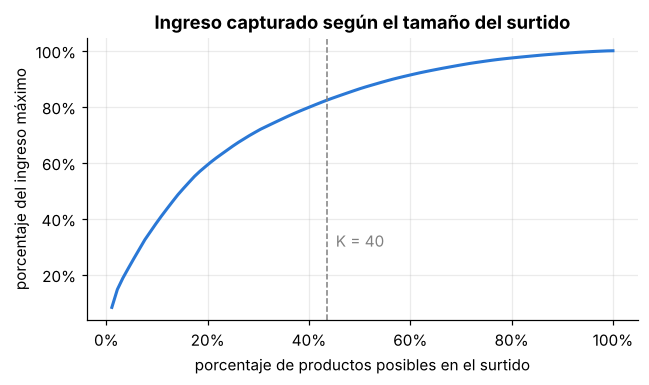

In [13]:
# Ingreso de la cadena con el surtido greedy de k productos, para k de 1 a 92 (figura 1 del artículo)
curva = np.array([ingreso(modelo, surtido(orden_cadena, k, N_PROD)).sum() for k in range(1, N_PROD + 1)])

fig, ax = plt.subplots(figsize=(6, 3.6))  # Crear la figura
# Porcentaje del ingreso máximo frente al porcentaje de productos en el surtido
ax.plot(np.arange(1, N_PROD + 1) / N_PROD, curva / curva[-1], color=COLOR[0], lw=2)
# Marcar el surtido de 40 productos
ax.axvline(40 / N_PROD, color="grey", ls="--", lw=1)
ax.annotate("K = 40", (40 / N_PROD, 0.3), xytext=(6, 0), textcoords="offset points", color="grey")  # Etiqueta de la línea
ax.set(title="Ingreso capturado según el tamaño del surtido", xlabel="porcentaje de productos posibles en el surtido",
       ylabel="porcentaje del ingreso máximo")
ax.xaxis.set_major_formatter("{x:.0%}")  # Eje x en porcentaje
ax.yaxis.set_major_formatter("{x:.0%}")  # Eje y en porcentaje
fig.tight_layout()  # Ajustar márgenes
fig.savefig(RUTA["figures"] / "02_ingreso_vs_tamano.png", bbox_inches="tight")  # Guardar la figura
plt.show()  # Mostrar la figura

La curva muestra que pocos productos capturan casi todo el ingreso. Por eso el espacio en el estante vale tanto. Después de cierto punto, cada producto adicional aporta poco, y conviene usar ese espacio para productos que sí roten.

## 9. Grupos de tiendas y beneficio de localizar (sección 5.5 y tabla 8)

Manejar un surtido distinto en cada una de las 140 tiendas es muy costoso, porque cada surtido necesita su propio planograma. El artículo limita a $L$ el número de surtidos distintos y usa un greedy hacia adelante. Empieza con el surtido de cadena y en cada paso agrega el surtido de tienda que más sube el ingreso total, asignando cada tienda al surtido que más le conviene. Las tiendas asignadas al mismo surtido forman un cluster.

Como en el artículo, usamos $K = 40$ para todas las tiendas y calculamos el ingreso para $L$ de 1 a 6 y para $L = 140$.

In [14]:
# Surtidos candidatos: el de cadena y el óptimo de cada tienda, todos con 40 productos
candidatos = np.vstack([S_cadena40, surtido(orden_tienda, 40, N_PROD)])
# Ingreso de cada tienda con cada surtido candidato (tiendas en filas, candidatos en columnas)
R = np.stack([ingreso(modelo, c) for c in candidatos], axis=1)

# Greedy hacia adelante: empezar con el surtido de cadena
cartera, ingreso_L = [0], [R[:, 0].sum()]
for _ in range(5):  # Agregar cinco surtidos más hasta tener seis
    # Ingreso total si se agrega cada candidato y cada tienda elige su mejor surtido
    total = np.maximum(R[:, cartera].max(1, keepdims=True), R).sum(0)
    # Agregar el candidato que más sube el ingreso
    cartera.append(int(total.argmax()))
    ingreso_L.append(total.max())  # Guardar el ingreso con ese número de surtidos
# Ingreso con un surtido propio en cada tienda (L = 140)
ingreso_m = R[np.arange(len(tiendas)), np.arange(len(tiendas)) + 1].sum()

# Tabla 8: ingreso según el número de surtidos y porcentaje del beneficio máximo que se captura
tabla8 = pd.DataFrame({"ingreso (millones)": np.append(ingreso_L, ingreso_m) / 1e6,
                       "artículo (millones)": [7.38, 7.62, 7.75, 7.86, 7.92, 7.94, 8.11]}, index=[1, 2, 3, 4, 5, 6, 140])
tabla8.index.name = "L"  # Nombre del índice
tabla8["beneficio capturado"] = (tabla8.iloc[:, 0] - tabla8.iloc[0, 0]) / (tabla8.iloc[-1, 0] - tabla8.iloc[0, 0])
tabla8["capturado en el artículo"] = (tabla8.iloc[:, 1] - 7.38) / (8.11 - 7.38)  # Lo mismo con los valores del artículo
tabla8  # Mostrar la tabla

,ingreso (millones),artículo (millones),beneficio capturado,capturado en el artículo
L,,,,
1,5.890,7.380,0.000,0.000
2,6.062,7.620,0.227,0.329
3,6.226,7.750,0.442,0.507
4,6.356,7.860,0.613,0.658
5,6.424,7.920,0.703,0.740
6,6.443,7.940,0.728,0.767
140,6.650,8.110,1.000,1.000


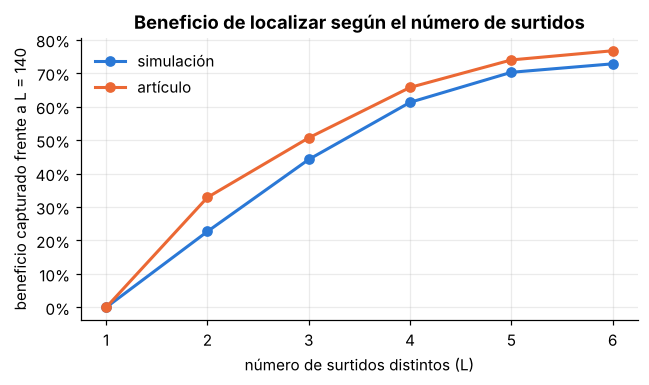

In [15]:
fig, ax = plt.subplots(figsize=(6, 3.6))  # Crear la figura
# Beneficio capturado según el número de surtidos, nuestro y del artículo
ax.plot(range(1, 7), tabla8["beneficio capturado"].iloc[:6], marker="o", color=COLOR[0], lw=2, label="simulación")
ax.plot(range(1, 7), tabla8["capturado en el artículo"].iloc[:6], marker="o", color=COLOR[1], lw=2, label="artículo")
ax.set(title="Beneficio de localizar según el número de surtidos", xlabel="número de surtidos distintos (L)",
       ylabel="beneficio capturado frente a L = 140")
ax.yaxis.set_major_formatter("{x:.0%}")  # Eje y en porcentaje
ax.legend(frameon=False)  # Leyenda
fig.tight_layout()  # Ajustar márgenes
fig.savefig(RUTA["figures"] / "03_beneficio_localizacion.png", bbox_inches="tight")  # Guardar la figura
plt.show()  # Mostrar la figura

Ahora miramos los clusters que salen con $L = 6$. Cada tienda queda en el grupo del surtido que más ingreso le da. Como los datos son simulados, podemos comparar estos grupos con los cuatro tipos de tienda ocultos usando el índice de Rand ajustado, que vale 1 si los grupos coinciden por completo con los tipos y cerca de 0 si no tienen relación. El método nunca vio el tipo oculto, así que esta comparación es solo una prueba de que los grupos tienen sentido.

In [16]:
# Hacer clusters: cada tienda queda en el surtido de la cartera que más ingreso le da
tiendas["cluster"] = R[:, cartera].argmax(1) + 1
# Perfil de cada cluster: tamaño, productos de marca 2 y cuota estimada de tamaño familiar
perfil = tiendas.assign(familiar=modelo["f"][:, catalogo["a2"] >= 2].sum(1),
                        marca2=modelo["f"][:, catalogo["a2"] % 2 == 1].sum(1)).groupby("cluster").agg(
    **{"tiendas": ("tienda", "size"), "tamaño medio": ("tamano", "mean"), "cuota familiar": ("familiar", "mean"),
       "cuota marca 2": ("marca2", "mean")})
# Productos del surtido de cada cluster que no están en el surtido de cadena
perfil["productos distintos al de cadena"] = [(candidatos[c] & ~S_cadena40[0]).sum() for c in cartera]
display(perfil)  # Mostrar el perfil de los clusters
# Comparar clusters con los tipos ocultos
print("Clusters frente a tipos ocultos de tienda")
display(pd.crosstab(tiendas["cluster"], tiendas["tipo"], colnames=["tipo oculto"]))  # Tabla cruzada de clusters y tipos
print(f"Índice de Rand ajustado: {adjusted_rand_score(tiendas['tipo'], tiendas['cluster']):.2f}")  # Qué tanto coinciden
# Guardar la asignación de tiendas
tiendas[["tienda", "cluster", "k_actual"]].to_csv(RUTA["results"] / "clusters_tiendas.csv", index=False)

,tiendas,tamaño medio,cuota familiar,cuota marca 2,productos distintos al de cadena
cluster,,,,,
1,1,0.765,0.097,0.256,0
2,16,1.451,0.087,0.448,11
3,33,1.184,0.115,0.259,17
4,40,0.974,0.217,0.351,10
5,32,0.969,0.153,0.337,9
6,18,0.830,0.082,0.505,20


Clusters frente a tipos ocultos de tienda


tipo oculto,0,1,2,3
cluster,,,,
1,0,0,0,1
2,16,0,0,0
3,0,0,0,33
4,0,40,0,0
5,0,0,32,0
6,18,0,0,0


Índice de Rand ajustado: 0.91


Los seis grupos recuperan casi por completo los cuatro tipos ocultos, con un índice de Rand ajustado cercano a 0,9. Algunos tipos quedan partidos en dos grupos y el surtido de cadena (grupo 1) termina usándolo muy pocas tiendas. Cada grupo lleva varios productos distintos al surtido de cadena, que son los de mayor rotación en ese tipo de tienda.

Para nuestro trabajo de grado esta es la parte de agrupar tiendas. Los grupos no se definen antes con variables de la tienda, sino a partir de la demanda estimada, y cada grupo sale ya con su surtido recomendado. Para evitar fuga de información, todo se calculó solo con las ventas de 2005.

## 10. Qué explica el beneficio de localizar (sección 6 y tabla 14)

El artículo encontró que el beneficio de tener surtidos por tienda frente a uno solo de cadena (llamado localization lift) no depende tanto de cuánto varía la demanda entre tiendas en general. Depende de cuánto varía la demanda de los productos que entran en el surtido óptimo de unas tiendas y no de otras, y de qué tanto del ingreso posible ya captura el surtido de cadena. Calculamos esas tres medidas con $K = 40$.

COV todos mide la variación entre tiendas de la cuota de ingreso de todos los productos. COV selección hace lo mismo pero solo con los productos que están en el surtido óptimo de algunas tiendas y no de todas. La cuota del óptimo de cadena es el ingreso del surtido de cadena dividido por el ingreso si se vendieran los 92 productos.

In [17]:
def cov(cuotas):
    """Coeficiente de variación de la demanda: raíz de la suma de varianzas sobre la suma de medias."""
    return np.sqrt(cuotas.var(0).sum()) / cuotas.mean(0).sum()


# Cuota de ingreso potencial de cada producto en cada tienda
cuota_ingreso = normalizar(modelo["f"] * modelo["p"])
# Productos que están en el óptimo de algunas tiendas pero no de todas
optimos = candidatos[1:]
seleccion = optimos.any(0) & ~optimos.all(0)  # Productos en algunos óptimos pero no en todos
# Tabla 14 del artículo frente a la simulación
pd.DataFrame({"artículo": [0.122, 0.17, 0.23, 0.71],
              "simulación": [ingreso_m / ingreso_L[0] - 1, cov(cuota_ingreso), cov(cuota_ingreso[:, seleccion]),
                             ingreso_L[0] / ingreso(modelo, np.ones(N_PROD, bool)).sum()]},
             index=["beneficio de localizar", "COV todos", "COV selección", "cuota del óptimo de cadena"])

,artículo,simulación
beneficio de localizar,0.122,0.129
COV todos,0.170,0.141
COV selección,0.230,0.144
cuota del óptimo de cadena,0.710,0.823


El beneficio de localizar queda muy cerca del artículo. La cuota del óptimo de cadena es más alta que en el artículo y los COV son algo menores, lo que indica que en nuestra simulación las tiendas se parecen un poco más entre sí. El patrón general coincide con el artículo. El beneficio de localizar es mayor cuanto menos ingreso captura un surtido único y cuanto más difieren las tiendas en los productos que están en el límite del surtido.

## 11. Pronóstico de un producto nuevo (sección 5.7)

En 2007 la cadena agregó un producto que nunca había vendido. Con los parámetros estimados en 2005 pronosticamos su cuota de ventas en cada tienda de 2007, sin haber visto una sola venta suya. Esto es posible porque el modelo conoce la demanda de su sabor y la de su marca y tamaño por separado. El artículo reporta un error absoluto porcentual de 16,2% para este caso.

In [18]:
# Producto nuevo de 2007: el que está en el surtido de 2007 y no en el de 2005
nuevo = np.flatnonzero(S_val.any(0) & ~S_fit.any(0))[0]
# Cuota pronosticada con los parámetros de 2005 y el surtido de 2007
pronostico = normalizar(prob_compra(modelo_val["f"], modelo_val["Pc"], S_val, EST) * S_val)[:, nuevo]
# Unidades pronosticadas en la cadena: cuota pronosticada por las ventas de cada tienda
unidades_nuevo = (pronostico * X_val.sum(1)).sum()
error_nuevo = abs(unidades_nuevo / X_val[:, nuevo].sum() - 1)  # Error porcentual en la cadena
pd.Series({"producto nuevo": " ".join(catalogo.loc[nuevo, ["sabor", "marca_tam"]]),
           "cuota real en la cadena": f"{X_val[:, nuevo].sum() / X_val.sum():.2%}",
           "cuota pronosticada en la cadena": f"{unidades_nuevo / X_val.sum():.2%}",
           "error porcentual (artículo 16,2%)": f"{error_nuevo:.1%}"}, name="valor")

producto nuevo                       Sabor 01 B2 Individual
cuota real en la cadena                               5.63%
cuota pronosticada en la cadena                       5.51%
error porcentual (artículo 16,2%)                      2.1%
Name: valor, dtype: str

El pronóstico del producto nuevo queda muy cerca de su cuota real. En el artículo el error fue de 16,2%, mayor que el nuestro, porque en datos reales un producto nuevo tiene características propias que no se explican solo por su sabor y su marca. La idea de fondo es la misma. El modelo puede estimar cuánto vendería un producto que nunca se ha vendido, que es lo que se necesita para decidir qué incorporar.

## 12. Comparación con los resultados del artículo

Reunimos en una tabla los resultados del artículo para los ponqués y los nuestros, y la guardamos en la carpeta results.

In [19]:
# Tabla resumen: resultado del artículo frente a la recreación con datos simulados
resumen = pd.DataFrame({
    "artículo": [0.062, 0.164, 0.258, 0.401, 0.292, 0.414, 0.122, 0.767, 0.162],
    "recreación": [*error.iloc[0, [1, 0]], *error.iloc[1, [1, 0]], *comparacion["aumento estimado"].iloc[1:],
                   tabla8.iloc[-1, 0] / tabla8.iloc[0, 0] - 1, tabla8.loc[6, "beneficio capturado"],
                   error_nuevo]},
    index=["MAD cadena en ajuste", "MAD tienda en ajuste", "MAD cadena en validación", "MAD tienda en validación",
           "aumento con surtido óptimo de cadena", "aumento con surtido óptimo por tienda",
           "beneficio de localizar (L = 140 frente a L = 1)", "beneficio capturado con 6 surtidos",
           "error del pronóstico del producto nuevo"])
resumen.to_csv(RUTA["results"] / "comparacion_articulo.csv")  # Guardar la tabla
resumen  # Mostrar la tabla

,artículo,recreación
MAD cadena en ajuste,0.062,0.008
MAD tienda en ajuste,0.164,0.069
MAD cadena en validación,0.258,0.065
MAD tienda en validación,0.401,0.284
aumento con surtido óptimo de cadena,0.292,0.239
aumento con surtido óptimo por tienda,0.414,0.380
beneficio de localizar (L = 140 frente a L = 1),0.122,0.129
beneficio capturado con 6 surtidos,0.767,0.728
error del pronóstico del producto nuevo,0.162,0.021


**Lectura de la comparación.** La recreación reproduce las conclusiones principales del artículo. El surtido optimizado vende bastante más que el actual, tanto con un surtido único de cadena como con uno por tienda, y el orden de magnitud es parecido al del artículo. El beneficio de localizar queda muy cerca del 12,2% reportado, y con solo seis surtidos se captura cerca de tres cuartas partes de ese beneficio, igual que en el artículo. Para nuestro trabajo de grado es la conclusión más útil, porque dice que no hace falta un surtido distinto en cada tienda y basta con agrupar las tiendas parecidas.

Las diferencias más claras están en el error de las estimaciones. En el ajuste nuestro error es menor porque los datos salen del mismo modelo que se estima. En la validación el error crece mucho, como en el artículo, aunque queda por debajo del reportado porque supusimos un cambio de gustos moderado. Por la misma razón el pronóstico del producto nuevo sale mejor. Por último, las probabilidades de sustitución entre marcas individuales salen más altas que las verdaderas, porque el surtido actual casi no deja ver qué pasa cuando falta una marca.

## 13. Aplicación a datos públicos con yogur de The Complete Journey

Buscamos datos abiertos con la misma forma que los del artículo, es decir ventas por tienda y producto, con atributos de cada producto. El que mejor se ajusta es The Complete Journey de dunnhumby, que tiene un año de compras (2017) de 2.469 hogares en cientos de tiendas de una cadena de supermercados de Estados Unidos. Incluye para cada producto el fabricante, si es marca nacional o marca propia, el tipo y el tamaño del empaque. Está publicado de forma abierta en el repositorio del paquete completejourney (github.com/bradleyboehmke/completejourney).

Elegimos la categoría de yogur porque es un lácteo, como los productos de nuestro trabajo de grado. Definimos los atributos así. El atributo 1 es el formato (individual de menos de 16 onzas, familiar de 16 onzas o más, y multiempaque). El atributo 2 es la marca, con la marca propia de la cadena, y las dos marcas nacionales más grandes, que llamamos A y B. Las demás marcas suman cerca del 1% de las unidades y faltan en muchas tiendas, así que las dejamos fuera. El cliente puede cambiar de marca dentro del mismo formato pero no de formato, igual que en los ponqués no se cambia de tamaño. Usamos una probabilidad de sustitución por marca de origen, y si hay varias marcas disponibles el cliente va a la que más vende en la cadena.

Hay tres diferencias con el artículo que conviene tener presentes. Los datos son de un panel de hogares, así que las ventas por tienda son pequeñas. No se observa el surtido, así que suponemos que una tienda tiene un producto si lo vendió en el periodo. Y no hay un atributo de sabor. Usamos las tiendas con al menos 150 unidades de yogur en cada semestre, el primer semestre como ajuste y el segundo como validación.

Otros datos públicos parecidos son Dominick's Finer Foods (Kilts Center de la Universidad de Chicago), con ventas semanales por producto en 100 supermercados y datos demográficos de cada tienda, que es libre para uso académico pero requiere descargarlo a mano. Corporación Favorita (Kaggle) tiene ventas diarias por tienda y producto en 54 tiendas, con una marca de producto perecedero, pero casi sin atributos de producto.

In [20]:
# Instalar pyreadr si no está (sirve para leer archivos de R)
try:
    import pyreadr
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyreadr"], check=True)  # Instalarlo con pip
    import pyreadr

# Descargar transacciones y productos del repositorio público (solo la primera vez)
URL_CJ = "https://raw.githubusercontent.com/bradleyboehmke/completejourney/master/data/"
for archivo in ("transactions.rds", "products.rda"):  # Recorrer los dos archivos
    if not (RUTA["data"] / archivo).exists():  # Revisar si ya está descargado
        urllib.request.urlretrieve(URL_CJ + archivo, RUTA["data"] / archivo)  # Descargar el archivo

# Cargar productos y quedarse con la categoría de yogur
yogur = next(iter(pyreadr.read_r(RUTA["data"] / "products.rda").values())).query("product_category == 'YOGURT'")
# Cargar transacciones y unirlas con los productos de yogur
trans = pyreadr.read_r(RUTA["data"] / "transactions.rds")[None].merge(yogur, on="product_id")

# Onzas del empaque para definir el formato
onzas = trans["package_size"].str.extract(r"(\d+\.?\d*)\s*OZ", expand=False).astype(float)
# Atributo 1: formato del empaque
trans["formato"] = np.select([trans["product_type"].eq("YOGURT MULTI-PACKS"), onzas >= 16],
                             ["Multiempaque", "Familiar"], "Individual")
# Atributo 2: marca (el fabricante 69 es la marca propia de la cadena)
trans["marca"] = trans["manufacturer_id"].map({"69": "Propia", "1487": "Marca A", "759": "Marca B"}).fillna("Otras")
# Periodo: primer semestre para ajuste y segundo para validación
trans["periodo"] = np.where(trans["week"] <= 26, "ajuste", "validacion")
# Dejar fuera las marcas pequeñas, que son cerca del 1% de las unidades y faltan en muchas tiendas
trans = trans[trans["marca"] != "Otras"]
# Tiendas con al menos 150 unidades de yogur en cada semestre
minimo = trans.pivot_table(index="store_id", columns="periodo", values="quantity", aggfunc="sum").fillna(0).min(axis=1)
trans = trans[trans["store_id"].isin(minimo[minimo >= 150].index)]  # Filtrar esas tiendas
print(f"{trans['store_id'].nunique()} tiendas, {len(trans)} líneas de compra, {trans['quantity'].sum():.0f} unidades")

49 tiendas, 17596 líneas de compra, 29979 unidades


In [21]:
# Productos del modelo: cada combinación de formato y marca
FORMATOS, MARCAS = ["Individual", "Familiar", "Multiempaque"], ["Propia", "Marca A", "Marca B"]
celdas = pd.MultiIndex.from_product([FORMATOS, MARCAS], names=["formato", "marca"]).to_frame(index=False)  # Tabla de los 9 productos
# Código del producto en las transacciones
trans["producto"] = trans["formato"].map(FORMATOS.index) * len(MARCAS) + trans["marca"].map(MARCAS.index)
# Precio promedio por unidad de cada producto en el periodo de ajuste
ajuste = trans.query("periodo == 'ajuste'")
celdas["precio"] = ajuste.groupby("producto")["sales_value"].sum() / ajuste.groupby("producto")["quantity"].sum()
# Si algún producto no se vendió en el ajuste, usar el precio promedio de su formato
celdas["precio"] = celdas["precio"].fillna(celdas.groupby("formato")["precio"].transform("mean"))
# Prioridad de sustitución: la marca que más vende en la cadena
prioridad = celdas["marca"].map(ajuste.groupby("marca")["quantity"].sum())
# Estructura: cambio de marca dentro del mismo formato, un parámetro por marca de origen
EST_Y = estructura(celdas.index // len(MARCAS), celdas.index % len(MARCAS),
                   {(a, b): a for a in range(len(MARCAS)) for b in range(len(MARCAS)) if a != b}, prioridad)

# Matrices tienda por producto (un producto está en el surtido si se vendió en el periodo)
ids_y = np.sort(trans["store_id"].unique())
unidades = trans.rename(columns={"store_id": "tienda", "quantity": "unidades"})  # Nombres de columnas que espera la función matrices
Xy_fit, _ = matrices(unidades.query("periodo == 'ajuste'"), ids_y, len(celdas))
Xy_val, _ = matrices(unidades.query("periodo == 'validacion'"), ids_y, len(celdas))
Sy_fit, Sy_val = Xy_fit > 0, Xy_val > 0  # Surtido de cada periodo
print(f"Productos por tienda en el ajuste: entre {Sy_fit.sum(1).min()} y {Sy_fit.sum(1).max()}, promedio {Sy_fit.sum(1).mean():.1f}")

Productos por tienda en el ajuste: entre 4 y 9, promedio 7.2


In [22]:
# Estimar el modelo de cada tienda con el primer semestre
modelo_y = estimar_cadena(Xy_fit, Sy_fit, EST_Y, celdas["precio"])
# Cuota de demanda estimada frente a cuota de ventas por marca
display(pd.DataFrame({"cuota de demanda estimada": [modelo_y["f"][:, celdas["marca"] == m].sum(1).mean() for m in MARCAS],
                      "cuota de ventas": [Xy_fit[:, celdas["marca"] == m].sum() / Xy_fit.sum() for m in MARCAS],
                      "probabilidad de sustituir (promedio)": modelo_y["pi"].mean(0)},
                     index=MARCAS))
# Validación con el segundo semestre
pd.DataFrame([mad(Xy_fit, Sy_fit, modelo_y), mad(Xy_val, Sy_val, modelo_y)], index=["ajuste", "validación"],
             columns=["MAD tienda", "MAD cadena"])

,cuota de demanda estimada,cuota de ventas,probabilidad de sustituir (promedio)
Propia,0.398,0.391,0.000
Marca A,0.307,0.320,0.000
Marca B,0.295,0.289,0.647


,MAD tienda,MAD cadena
ajuste,0.145,0.122
validación,0.433,0.204


In [23]:
# Greedy de cadena y por tienda con todos los productos posibles
orden_cy = greedy(modelo_y, len(celdas), por_tienda=False)
orden_ty = greedy(modelo_y, len(celdas), por_tienda=True)  # Greedy por tienda
# Comparar con el mismo número de productos que hoy tiene cada tienda
ky = Sy_fit.sum(1)
surtidos_y = {"actual": Sy_fit, "óptimo de cadena": surtido(np.tile(orden_cy, (len(ids_y), 1)), ky, len(celdas)),
              "óptimo por tienda": surtido(orden_ty, ky, len(celdas))}
ingreso_y = pd.Series({k: ingreso(modelo_y, S).sum() for k, S in surtidos_y.items()}, name="ingreso estimado")  # Ingreso de cada surtido
display(pd.DataFrame({"ingreso estimado": ingreso_y, "aumento": ingreso_y / ingreso_y["actual"] - 1}))  # Mostrar el aumento frente al actual

# Clusters con espacio para 6 productos y hasta 4 surtidos distintos
cand_y = np.vstack([surtido(orden_cy, 6, len(celdas)), surtido(orden_ty, 6, len(celdas))])
Ry = np.stack([ingreso(modelo_y, c) for c in cand_y], axis=1)  # Ingreso de cada tienda con cada candidato
cartera_y = [0]  # Empezar con el surtido de cadena
for _ in range(3):  # Agregar tres surtidos más
    cartera_y.append(int(np.maximum(Ry[:, cartera_y].max(1, keepdims=True), Ry).sum(0).argmax()))  # El que más sube el ingreso total
# Asignar cada tienda a su mejor surtido
cluster_y = Ry[:, cartera_y].argmax(1) + 1
# Mostrar qué productos lleva cada surtido y cuántas tiendas tiene
pd.DataFrame({f"surtido {c + 1} ({(cluster_y == c + 1).sum()} tiendas)": cand_y[s] for c, s in enumerate(cartera_y)},
             index=celdas["formato"] + " " + celdas["marca"]).replace({True: "sí", False: ""})

,ingreso estimado,aumento
actual,12106.293,0.000
óptimo de cadena,13633.918,0.126
óptimo por tienda,13757.197,0.136


,surtido 1 (31 tiendas),surtido 2 (8 tiendas),surtido 3 (4 tiendas),surtido 4 (6 tiendas)
Individual Propia,sí,,sí,sí
Individual Marca A,sí,sí,sí,sí
Individual Marca B,sí,sí,,sí
Familiar Propia,,,sí,sí
Familiar Marca A,sí,sí,sí,
Familiar Marca B,,,,
Multiempaque Propia,sí,sí,sí,sí
Multiempaque Marca A,sí,sí,sí,sí
Multiempaque Marca B,,sí,,


**Lectura de los datos públicos.** El modelo separa la cuota de demanda de cada marca de su cuota de ventas, aunque en el yogur las dos quedan parecidas porque las tres marcas están en casi todas las tiendas. Según la estimación, quien prefiere la marca propia o la marca A casi nunca se cambia de marca si no la encuentra, mientras que buena parte de los clientes de la marca B sí lo hace. Hay que leer esto con cuidado, porque suponemos que un producto no está en la tienda cuando no se vendió, y en tiendas con pocas ventas un producto puede estar en el estante sin que ningún hogar del panel lo compre. El error de validación es alto, parecido al del artículo, porque las ventas por tienda de un panel de hogares son pocas y cambian mucho de un semestre a otro.

En la optimización, con el mismo número de productos que hoy tiene cada tienda, el surtido de cadena aumenta el ingreso estimado y el surtido por tienda lo aumenta un poco más. Con espacio para 6 productos aparecen cuatro surtidos. La mayoría de las tiendas comparte uno, y los demás grupos cambian sobre todo qué marcas llevan en cada formato. Este es el tipo de resultado que buscamos para Alquería en cada cadena, con la diferencia de que con datos de sell out de la cadena las ventas por tienda serían completas y no una muestra de hogares.

## 14. Conclusiones

Logramos recrear el procedimiento completo del artículo, desde la estimación de demanda con sustitución hasta la elección de surtidos y la agrupación de tiendas, y los resultados principales se parecen a los reportados. El surtido optimizado vende bastante más que el actual, un surtido por tienda vende más que uno de cadena, y con pocos surtidos distintos se captura la mayor parte de ese beneficio.

No pudimos usar los datos originales, así que los resultados dependen de los supuestos de la simulación, que quedaron escritos en la sección 3. Tampoco recreamos la implementación en tiendas reales ni las otras dos aplicaciones del artículo, que son llantas y químicos para autos.

Del método aprendimos tres cosas. La primera es que las ventas no son la demanda, porque están infladas por la sustitución y limitadas por el surtido, y el modelo permite separarlas. La segunda es que la sustitución solo se puede medir cuando los surtidos varían entre tiendas, y si no varían hay que apoyarse en la información del resto de la cadena. La tercera es que el error crece mucho cuando cambian los gustos, así que el modelo se debe reestimar con datos recientes.

Para nuestro trabajo de grado el artículo responde las tres preguntas del proyecto. Agrupa las tiendas que se comportan parecido, entiende qué atributos hacen que un producto venda en cada tienda y estima el potencial de cada producto, incluso de los que hoy no están. El resultado se traduce directamente en mantener, incorporar o retirar productos dentro del espacio que Alquería ya compró en cada cadena. Como los lácteos son perecederos, falta agregar el costo de los productos que se vencen, porque el artículo no considera inventario.